<a href="https://colab.research.google.com/github/anoporal/UMC-AI-Studies/blob/main/FLAML_vs_AutoSklearn_Breno_Maciel_6%C2%BAA_Matutino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dados do aluno

**Nome**: Breno Maciel de Assis

**RGM**: 11241101614

**Curso**: Engenharia de Software

**Período**: 6º A | Matutino

**Professor**: Fabiano Bezerra Menegidio

# Auto-Sklearn

In [ ]:
# Instalando dependências linux para compilar os pacotes do auto-sklearn
!sudo apt-get update
!sudo apt-get install -y build-essential swig python3-dev python3.8-dev python3.8-venv

# Criando virtual environment limpo, usando python 3.8
!python3.8 -m venv autosklearn_env

# Atualizando o pip, setuptools e wheel dentro do venv
!source autosklearn_env/bin/activate && pip install --upgrade pip setuptools wheel
# Instalando o auto-sklearn
!source autosklearn_env/bin/activate && pip install auto-sklearn matplotlib matplotlib_inline seaborn ipython

!pip install flaml

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [79.0 kB]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.6 MB]
Get:11 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.9 kB]
Get:13 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,

In [ ]:
# Retorno a listagem do pip
!source autosklearn_env/bin/activate && pip list

Package             Version
------------------- --------
asttokens           3.0.2
auto-sklearn        0.15.0
backcall            0.2.0
click               8.1.8
cloudpickle         3.1.2
ConfigSpace         0.4.21
contourpy           1.1.1
cycler              0.12.1
Cython              3.2.9
dask                2023.5.0
decorator           5.3.1
distributed         2023.5.0
distro              1.9.0
emcee               3.1.6
executing           2.3.0
fonttools           4.57.0
fsspec              2025.3.0
importlib_metadata  8.5.0
importlib_resources 6.4.5
ipython             8.12.3
jedi                0.19.2
Jinja2              3.1.6
joblib              1.4.2
kiwisolver          1.4.7
liac-arff           2.5.0
locket              1.0.0
MarkupSafe          2.1.5
matplotlib          3.7.5
matplotlib-inline   0.1.7
msgpack             1.1.1
numpy               1.24.4
packaging           26.2
pandas              2.0.3
parso               0.8.7
partd               1.4.1
pexpect           

In [ ]:
%%writefile auto-sklearn.py
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from autosklearn.classification import AutoSklearnClassifier

# Carregando os dados
X, y = sklearn.datasets.load_iris(return_X_y=True)
x_train, x_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y)

# Configurando e treinando o classificador do auto-sklearn
autosklearn = AutoSklearnClassifier(
    time_left_for_this_task=120,
    per_run_time_limit=30,
    resampling_strategy='holdout'
)

print("Iniciando o treinamento do Auto-Sklearn no ambiente virtual...")
autosklearn.fit(x_train, y_train)

# Gerando previsões e calculando métricas
y_pred = autosklearn.predict(x_test)
accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)

# Obtendo estatísticas das rodadas do AutoML
print(autosklearn.sprint_statistics())
print("Treinmaneto concluído e resultados exportados com sucesso!")

print("=== ESTATÍSTICAS DO AUTO-SKLEARN ===")
print(f"Acurácia Final: {accuracy:.4%}\n")

# Criando a matriz de confusão, com os resultados carregados
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="BuPu", xticklabels=["Setosa", "Versicolor", "Virginica"], yticklabels=["Setosa", "Versicolor", "Virginica"])
plt.title("Matriz de Confusão - Dados do Auto-Sklearn")
plt.xlabel("Previsão")
plt.ylabel("Real")

# Salvando a imagem para ser exibida depois
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.close()
print("Gráfico salvo com sucesso como 'confusion_matrix.png'")

Writing auto-sklearn.py


In [ ]:
!./autosklearn_env/bin/python auto-sklearn.py

Iniciando o treinamento do Auto-Sklearn no ambiente virtual...
[WARNING] [2026-11-13 17:48:08,168:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-13 17:48:09,317:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-13 17:48:15,685:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-13 17:48:17,070:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-13 17:48:20,223:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-13 17:48:22,033:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/eq

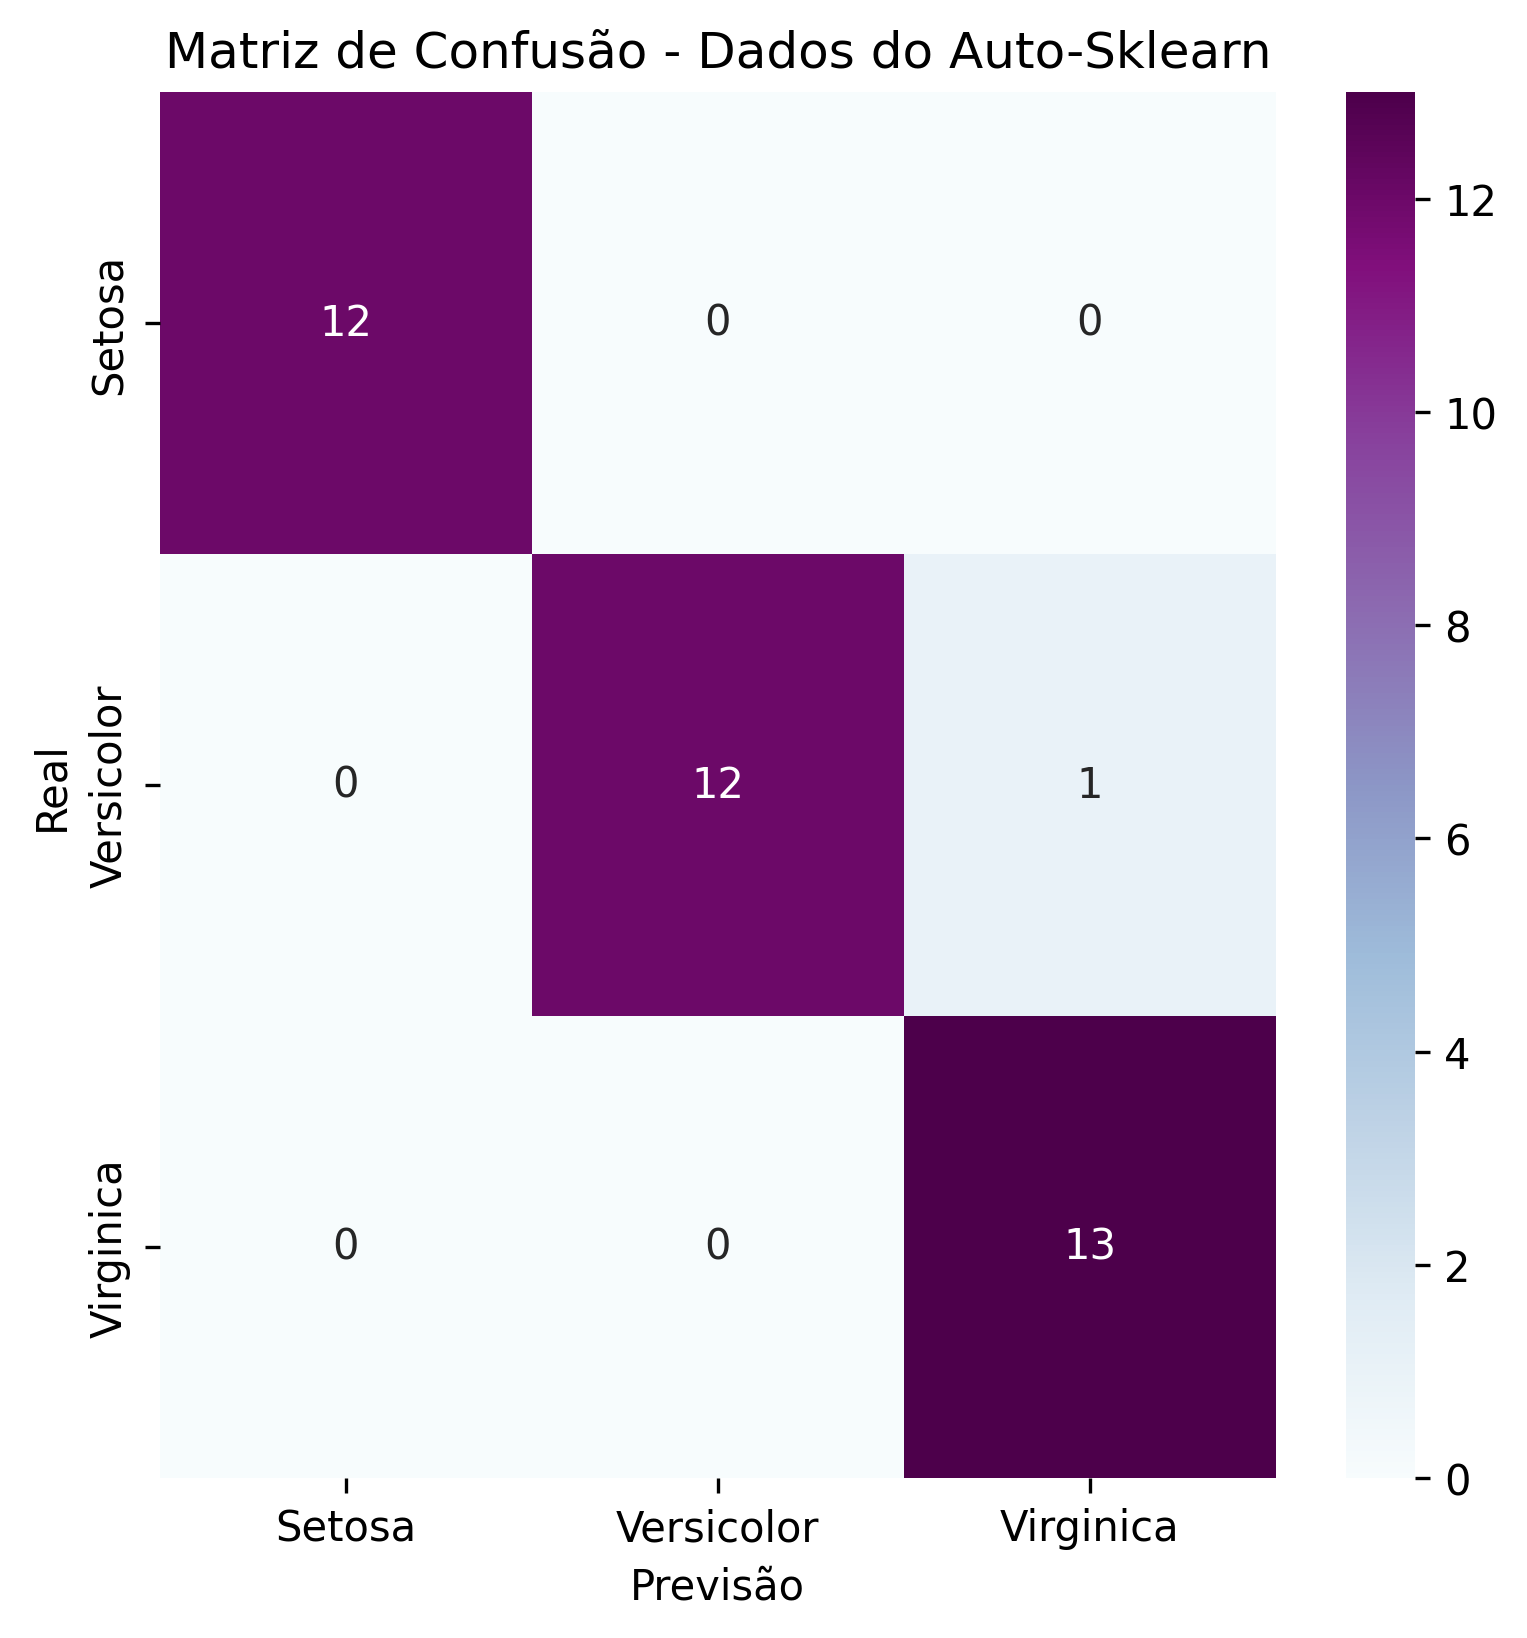

In [ ]:
from IPython.display import Image, display

# Exibindo a imagem gerada pelo script da célula anterior, executado no virtual environment
try:
  display(Image(filename='confusion_matrix.png'))
except FileNotFoundError:
  print("A imagem do gráfico não foi encontrada. Certifique-se de antes executar o script da célula anterior.")

# FLAML

Iniciando o treinamento do FLAML AutoML no virtual environment...
[flaml.automl.logger: 11-13 18:04:55] {2484} INFO - task = classification
[flaml.automl.logger: 11-13 18:04:55] {2495} INFO - Evaluation method: cv
[flaml.automl.logger: 11-13 18:04:55] {2604} INFO - Minimizing error metric: 1-accuracy
[flaml.automl.logger: 11-13 18:04:55] {2721} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 11-13 18:04:55] {3026} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 11-13 18:04:55] {3161} INFO - Estimated sufficient time budget=423s. Estimated necessary time budget=10s.
[flaml.automl.logger: 11-13 18:04:55] {3212} INFO -  at 0.1s,	estimator lgbm's best error=5.3360e-02,	best estimator lgbm's best error=5.3360e-02
[flaml.automl.logger: 11-13 18:04:55] {3026} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 11-13 18:04:55] {3212} INFO -  at 0.1s,	estimator lgbm's best error=5.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at 0.2s,	estimator sgd's best error=1.4269e-01,	best estimator lgbm's best error=3.5178e-02
[flaml.automl.logger: 11-13 18:04:56] {3026} INFO - iteration 4, current learner xgboost
[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at 0.3s,	estimator xgboost's best error=3.5573e-02,	best estimator lgbm's best error=3.5178e-02
[flaml.automl.logger: 11-13 18:04:56] {3026} INFO - iteration 5, current learner extra_tree
[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at 0.5s,	estimator extra_tree's best error=1.0672e-01,	best estimator lgbm's best error=3.5178e-02
[flaml.automl.logger: 11-13 18:04:56] {3026} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at 0.6s,	estimator lgbm's best error=3.5178e-02,	best estimator lgbm's best error=3.5178e-02
[flaml.automl.logger: 11-13 18:04:56] {3026} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at 0.8s,	estimator rf's best error=5.2964e-02,	best estimator lgbm's best error=3.5178e-02
[flaml.automl.logger: 11-13 18:04:56] {3026} INFO - iteration 9, current learner lgbm
[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at 0.8s,	estimator lgbm's best error=3.5178e-02,	best estimator lgbm's best error=3.5178e-02
[flaml.automl.logger: 11-13 18:04:56] {3026} INFO - iteration 10, current learner lgbm
[flaml.automl.logger: 11-13 18:04:56] {3212} INFO -  at 0.9s,	estimator lgbm's best error=3.5178e-02,	best estimator lgbm's best error=3.5178e-02
[flaml.automl.logger: 11-13 18:04:56] {3026} INFO - iteration 11, current learner rf


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

... (323 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[flaml.automl.logger: 11-13 18:06:54] {3212} INFO -  at 118.7s,	estimator extra_tree's best error=1.7787e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:54] {3026} INFO - iteration 845, current learner extra_tree
[flaml.automl.logger: 11-13 18:06:54] {3212} INFO -  at 118.9s,	estimator extra_tree's best error=1.7787e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:54] {3026} INFO - iteration 846, current learner extra_tree
[flaml.automl.logger: 11-13 18:06:55] {3212} INFO -  at 119.4s,	estimator extra_tree's best error=1.7787e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:55] {3026} INFO - iteration 847, current learner lgbm
[flaml.automl.logger: 11-13 18:06:55] {3212} INFO -  at 119.4s,	estimator lgbm's best error=3.5178e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:55] {3026} INFO - iteration 848, current learner lgbm
[f

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[flaml.automl.logger: 11-13 18:06:55] {3212} INFO -  at 119.6s,	estimator lrl1's best error=2.7273e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:55] {3026} INFO - iteration 851, current learner lrl1
[flaml.automl.logger: 11-13 18:06:55] {3212} INFO -  at 119.7s,	estimator lrl1's best error=2.7273e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:55] {3026} INFO - iteration 852, current learner extra_tree
[flaml.automl.logger: 11-13 18:06:55] {3212} INFO -  at 119.9s,	estimator extra_tree's best error=1.7787e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:55] {3026} INFO - iteration 853, current learner lrl1
[flaml.automl.logger: 11-13 18:06:55] {3212} INFO -  at 120.0s,	estimator lrl1's best error=2.7273e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-13 18:06:55] {3474} INFO - retrain extra_tree for 0.0s
[flaml.automl.logger: 11-13 

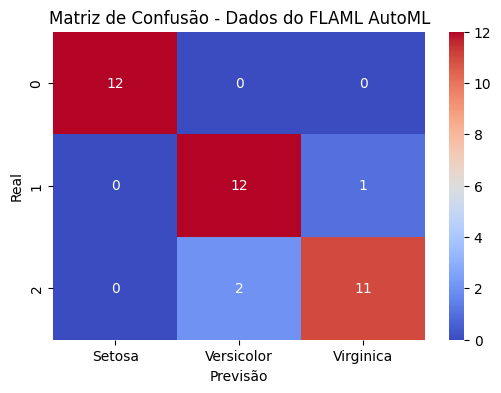

None

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from flaml import AutoML

# Carregando os dados
X, y = sklearn.datasets.load_iris(return_X_y=True)
X, y = pd.DataFrame(x), pd.Series(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y)

# Configurando e treinando o classificados do FLAML (AutoML)
automl = AutoML(
    time_budget=120,
    metric="accuracy",
    task="classification",
    log_file_name="flaml.log",
    seed=42
)

pipeline = Pipeline(steps=[
    ("prep", StandardScaler()),
    ("clf", automl)
])

print("Iniciando o treinamento do FLAML AutoML no virtual environment...")
pipeline.fit(X_train, y_train)

# Gerando previsões e calculando métricas
y_pred = pipeline.predict(X_test)
accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)

# Obtendo estatísticas do melhor modelo encontrado pelo FLAML
print("=== ESTATÍSTICAS DO FLAML ===")
print("Melhor modelo encontrado: ", automl.best_estimator)
print("Melhores hiperparâmetros: ", automl.best_config)
print(f"Melhor acurácia de validação: {1 - automl.best_loss:.4%}")
print(f"Acurácia final no teste: {accuracy:.4%}")

# Criando a matriz de confusão com os resultados do FLAML
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm", xticklabels=['Setosa', 'Versicolor', 'Virginica'])
plt.title("Matriz de Confusão - Dados do FLAML AutoML")
plt.xlabel("Previsão")
plt.ylabel("Real")
display(plt.show())

# Conclusão
Entre as bibliotecas AutoML, o **Auto-Sklearn** obteve uma acurácia de *97.3684%*, enquanto o **FLAML** obteve uma acurácia final de *92.1053%*.